# Term Deposit Marketing: Decision Trees and Random Forests

**Business context.** A Portuguese retail bank sells term deposits by phone. Every call costs agent time, and most clients say no:
only about 1 in 9 subscribes. The question is **which clients to call first**, so the campaign reaches more subscribers with fewer calls.

**Why trees?** A **decision tree** turns the data into plain if-then rules ("previous campaign succeeded → high chance") that a marketing team can read and challenge.
A **random forest** averages hundreds of trees for better accuracy, at the cost of that readability. This notebook builds both and compares them honestly,
including on a period the models never saw.

**Dataset.** *Bank Marketing* (UCI Machine Learning Repository; Moro, Cortez & Rita, 2014): 41,188 phone contacts from May 2008 to November 2010,
with client details, campaign history, economic indicators at the time of the call, and whether the client subscribed.

**Outline**
1. Setup and data loading
2. Data dictionary and data-quality checks
3. Leakage: the column that has to go
4. Feature preparation
5. Train/test split
6. Exploratory analysis
7. Decision tree: how it splits, how it overfits, how to prune it
8. Random forest
9. Model comparison
10. Gains and lift: who to call first
11. Calibration
12. Feature importance: impurity vs permutation
13. Campaign economics: how many clients to call
14. Out-of-time validation: does the model survive a changing economy?
15. Limitations and model ownership

> **How to read this notebook:** each section starts with *what* the step does and *why*.
> Code cells have inline comments (lines starting with `#`) explaining each line.

## 1. Setup and data loading

| Library | Used for |
|---|---|
| `pandas`, `numpy` | Data tables and maths |
| `matplotlib` | Charts |
| `scikit-learn` | Decision trees, random forests, logistic regression, pipelines, cross-validation, metrics, permutation importance |

In [1]:
import os, urllib.request
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import PercentFormatter

from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score, GridSearchCV
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.tree import DecisionTreeClassifier, plot_tree, export_text
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.inspection import permutation_importance
from sklearn.metrics import roc_auc_score, average_precision_score

pd.set_option("display.float_format", lambda x: f"{x:,.3f}")
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})
RANDOM_STATE = 42
TARGET = "subscribed"
NAVY, AMBER, RED, GREY = "#2C3E50", "#E8A33D", "#C0392B", "#95A5A6"
FIG_DIR = "../reports/figures"
os.makedirs(FIG_DIR, exist_ok=True)

In [2]:
DATA_DIR = "../data"
CSV_PATH = os.path.join(DATA_DIR, "bank-additional-full.csv")
URL = ("https://raw.githubusercontent.com/ahanagangopadhyay/improving-bank-telemarketing-campaigns/"
       "main/data/bank-additional-full.csv")

if not os.path.exists(CSV_PATH):          # download only if the file isn't already in data/
    os.makedirs(DATA_DIR, exist_ok=True)
    urllib.request.urlretrieve(URL, CSV_PATH)

raw = pd.read_csv(CSV_PATH, sep=";")      # note: the file uses semicolons, not commas
print(raw.shape)
raw.head()

(41188, 21)


,age,job,marital,education,default,housing,loan,contact,month,day_of_week,...,campaign,pdays,previous,poutcome,emp.var.rate,cons.price.idx,cons.conf.idx,euribor3m,nr.employed,y
0,56,housemaid,married,basic.4y,no,no,no,telephone,may,mon,...,1,999,0,nonexistent,1.100,93.994,-36.400,4.857,"5,191.000",no
1,57,services,married,high.school,unknown,no,no,telephone,may,mon,...,1,999,0,nonexistent,1.100,93.994,-36.400,4.857,"5,191.000",no
2,37,services,married,high.school,no,yes,no,telephone,may,mon,...,1,999,0,nonexistent,1.100,93.994,-36.400,4.857,"5,191.000",no
3,40,admin.,married,basic.6y,no,no,no,telephone,may,mon,...,1,999,0,nonexistent,1.100,93.994,-36.400,4.857,"5,191.000",no
4,56,services,married,high.school,no,no,yes,telephone,may,mon,...,1,999,0,nonexistent,1.100,93.994,-36.400,4.857,"5,191.000",no


## 2. Data dictionary and data-quality checks

| Group | Columns |
|---|---|
| **Client** | `age`; `job`; `marital`; `education`; `default` (credit in default?); `housing` (housing loan?); `loan` (personal loan?) |
| **This campaign's contact** | `contact` (cellular / telephone); `month`; `day_of_week`; `duration` (call length, seconds); `campaign` (calls to this client in this campaign) |
| **Earlier campaigns** | `pdays` (days since last contact; **999 = never contacted**); `previous` (contacts before this campaign); `poutcome` (outcome of the previous campaign) |
| **Economy at the time** | `emp.var.rate` (employment variation rate); `cons.price.idx` (consumer price index); `cons.conf.idx` (consumer confidence index); `euribor3m` (3-month Euribor interest rate, %); `nr.employed` (employment, thousands) |
| **Target** | `y`: did the client subscribe to a term deposit? |

The rows are in **date order**, May 2008 to November 2010. Section 14 uses that.

In [3]:
print("Missing values:   ", raw.isna().sum().sum())
print("Duplicate rows:   ", raw.duplicated().sum())
print(f"Subscription rate: {(raw['y'] == 'yes').mean():.2%}  ({(raw['y'] == 'yes').sum():,} of {len(raw):,})")
print("\n'unknown' values per column:")
print((raw == "unknown").sum()[lambda s: s > 0].to_string())
print("\ndefault:", raw["default"].value_counts().to_dict())
print(f"pdays = 999 (never contacted before): {(raw['pdays'] == 999).mean():.1%} of rows")

Missing values:    0
Duplicate rows:    12
Subscription rate: 11.27%  (4,640 of 41,188)

'unknown' values per column:
job           330
marital        80
education    1731
default      8597
housing       990
loan          990

default: {'no': 32588, 'unknown': 8597, 'yes': 3}
pdays = 999 (never contacted before): 96.3% of rows


**Data-quality findings**

| Issue | Detail | Decision |
|---|---|---|
| Missing values | None as blanks, but several columns use the category `unknown` | Keep `unknown` as its own category: "not disclosed" can carry information |
| Duplicates | 12 exact duplicate rows | Remove |
| `default` | Only 3 clients say "yes"; 21% are `unknown` | Keep; in practice it separates "no" from "unknown" |
| `pdays = 999` | A code for "never contacted before", not a real 999 days | Recode to −1, so a tree can isolate it with one split instead of treating it as a huge number |
| Class balance | 11.3% subscribe | Stratify the split; judge models by ranking metrics, not accuracy (predicting "no" for everyone is 88.7% accurate and useless) |

## 3. Leakage: the column that has to go

`duration` is the length of the call in seconds. It is strongly linked to the outcome, since clients who subscribe stay on the line longer,
but it is **only known after the call has happened**. A model that uses it can't be used to decide *whom to call*.
The dataset's own documentation says it should be discarded for a realistic predictive model. Here is what it would do to the results:

In [4]:
df = raw.drop_duplicates().reset_index(drop=True)     # keep chronological order
df[TARGET] = (df["y"] == "yes").astype(int)
df["pdays"] = df["pdays"].replace(999, -1)            # 999 = never contacted before

CATEGORICAL = ["job", "marital", "education", "default", "housing", "loan", "contact", "month", "day_of_week", "poutcome"]
NUMERIC = ["age", "campaign", "pdays", "previous", "emp.var.rate", "cons.price.idx", "cons.conf.idx", "euribor3m", "nr.employed"]
FEATURES = CATEGORICAL + NUMERIC

def tree_pipeline(numeric_cols, **params):
    prep = ColumnTransformer([("cat", OneHotEncoder(handle_unknown="ignore"), CATEGORICAL)],
                             remainder="passthrough", verbose_feature_names_out=False)
    return Pipeline([("prep", prep), ("model", DecisionTreeClassifier(random_state=RANDOM_STATE, **params))])

a_tr, a_te = train_test_split(df, test_size=0.2, stratify=df[TARGET], random_state=RANDOM_STATE)
for label, cols in [("with duration", NUMERIC + ["duration"]), ("without duration", NUMERIC)]:
    m = tree_pipeline(cols, max_depth=6).fit(a_tr[CATEGORICAL + cols], a_tr[TARGET])
    print(f"Decision tree {label:17s}: test AUC = {roc_auc_score(a_te[TARGET], m.predict_proba(a_te[CATEGORICAL + cols])[:, 1]):.3f}")

Decision tree with duration    : test AUC = 0.935
Decision tree without duration : test AUC = 0.800


An AUC of 0.94 would look impressive in a portfolio, and it would be meaningless in production. **`duration` is dropped.** Every result from here on
uses only information available *before* the call.

## 4. Feature preparation

- **Categorical columns** are one-hot encoded: `job = student` becomes a 0/1 column. Trees can then split on "is the client a student?".
- **Numeric columns** are passed through unchanged. Trees split on thresholds (`age ≤ 60.5`), so scaling makes no difference to them.
- **The five economic indicators** are kept. They are known on the day of the call, so using them isn't leakage,
  but they change slowly over time, which matters a lot in Section 14.

In [5]:
data = df.drop(columns=["y", "duration"])
print(f"{len(data):,} rows, {len(FEATURES)} features ({len(CATEGORICAL)} categorical, {len(NUMERIC)} numeric)")

41,176 rows, 19 features (10 categorical, 9 numeric)


## 5. Train/test split

20% of clients are held back as a test set, untouched until Section 9. `stratify` keeps the 11.3% subscription rate identical in both parts.
(Section 14 adds a second, tougher test: training on earlier months and testing on later ones.)

In [6]:
train, test = train_test_split(data, test_size=0.2, stratify=data[TARGET], random_state=RANDOM_STATE)
X_train, y_train = train[FEATURES], train[TARGET]
X_test, y_test = test[FEATURES], test[TARGET]
print(f"Train: {len(train):,} clients, subscription rate {y_train.mean():.2%}")
print(f"Test:  {len(test):,} clients, subscription rate {y_test.mean():.2%}")

Train: 32,940 clients, subscription rate 11.27%
Test:  8,236 clients, subscription rate 11.27%


## 6. Exploratory analysis

**What this does:** looks at subscription rates for a few columns that a marketing team would ask about first.

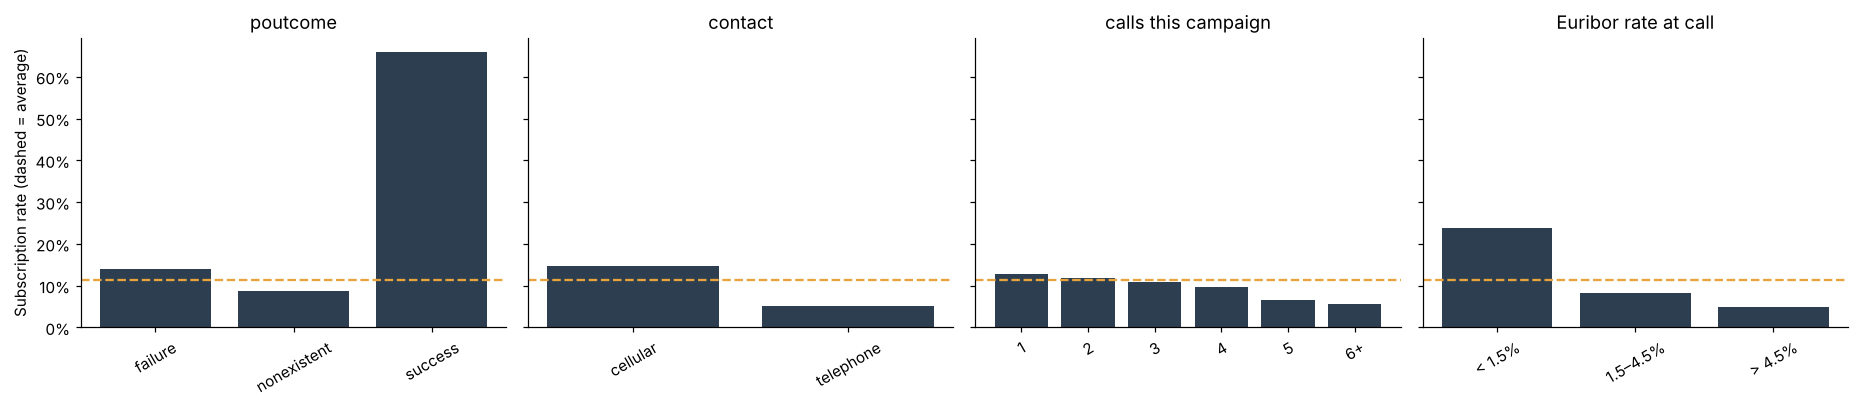

In [7]:
fig, axes = plt.subplots(1, 4, figsize=(17, 3.8), sharey=True)
eur_band = pd.cut(train["euribor3m"], [0, 1.5, 4.5, 6], labels=["< 1.5%", "1.5–4.5%", "> 4.5%"])
groups = [("poutcome", train["poutcome"]), ("contact", train["contact"]),
          ("calls this campaign", train["campaign"].clip(upper=6).replace(6, "6+").astype(str)),
          ("Euribor rate at call", eur_band)]
for ax, (title, g) in zip(axes, groups):
    rate = train.groupby(g, observed=True)[TARGET].mean()
    ax.bar(rate.index.astype(str), rate.values, color=NAVY)
    ax.axhline(y_train.mean(), color=AMBER, ls="--", lw=1.5)
    ax.set_title(title); ax.yaxis.set_major_formatter(PercentFormatter(1)); ax.tick_params(axis="x", rotation=30)
axes[0].set_ylabel("Subscription rate (dashed = average)")
plt.tight_layout(); plt.savefig(f"{FIG_DIR}/01_subscription_rates.png", dpi=120, bbox_inches="tight"); plt.show()

**Takeaways**
- **A previous success is the strongest single signal**: clients who said yes last time subscribe about 65% of the time.
- **Mobile contacts convert better** than landlines.
- **Diminishing returns from repeat calls**: every extra call in the same campaign lowers the rate.
- **The economy matters enormously**: when the Euribor rate was low (2009 onwards), subscription rates were several times higher than in 2008.

## 7. Decision tree

### 7a. How a tree chooses a split: Gini impurity

A node's **Gini impurity** is the chance of mislabelling a randomly chosen client if you labelled them randomly by the node's mix:

$$\text{Gini} = 1 - p_{yes}^2 - p_{no}^2$$

A pure node (all yes or all no) has Gini 0. At each step the tree tries every possible split and keeps the one with the largest drop
in **weighted** impurity: parent Gini − (share left × Gini left + share right × Gini right).

Below: the root split of a one-level tree, worked by hand.

In [8]:
stump = tree_pipeline(NUMERIC, max_depth=1).fit(X_train, y_train)
names = stump.named_steps["prep"].get_feature_names_out()
t = stump.named_steps["model"].tree_
feature, threshold = names[t.feature[0]], t.threshold[0]
print(f"Root split chosen: {feature} <= {threshold:.2f}\n")

Xt = stump.named_steps["prep"].transform(X_train)
left = Xt[:, t.feature[0]] <= threshold
def gini(y):
    p = y.mean()
    return 1 - p**2 - (1 - p)**2

y_arr = y_train.values
g_parent, g_left, g_right = gini(y_arr), gini(y_arr[left]), gini(y_arr[~left])
w_left = left.mean()
print(f"Parent:  {len(y_arr):,} clients, yes rate {y_arr.mean():.3f}, Gini = 1 - {y_arr.mean():.3f}² - {1 - y_arr.mean():.3f}² = {g_parent:.4f}")
print(f"Left:    {left.sum():,} clients ({w_left:.1%}), yes rate {y_arr[left].mean():.3f}, Gini = {g_left:.4f}")
print(f"Right:   {(~left).sum():,} clients ({1 - w_left:.1%}), yes rate {y_arr[~left].mean():.3f}, Gini = {g_right:.4f}")
weighted = w_left * g_left + (1 - w_left) * g_right
print(f"\nWeighted child Gini = {w_left:.3f} x {g_left:.4f} + {1 - w_left:.3f} x {g_right:.4f} = {weighted:.4f}")
print(f"Impurity decrease   = {g_parent:.4f} - {weighted:.4f} = {g_parent - weighted:.4f}  (the largest of any possible split)")

Root split chosen: nr.employed <= 5087.65

Parent:  32,940 clients, yes rate 0.113, Gini = 1 - 0.113² - 0.887² = 0.1999
Left:    3,987 clients (12.1%), yes rate 0.441, Gini = 0.4930
Right:   28,953 clients (87.9%), yes rate 0.067, Gini = 0.1258

Weighted child Gini = 0.121 x 0.4930 + 0.879 x 0.1258 = 0.1703
Impurity decrease   = 0.1999 - 0.1703 = 0.0297  (the largest of any possible split)


The first split is on **employment** (`nr.employed`), an economic indicator, not a client characteristic: the economy sets the baseline
for everyone, and client details then move individuals up or down from it.

### 7b. An unrestricted tree memorises the training data

In [9]:
full = tree_pipeline(NUMERIC).fit(X_train, y_train)          # no limits at all
print(f"Unrestricted tree: {full.named_steps['model'].get_n_leaves():,} leaves, depth {full.named_steps['model'].get_depth()}")
print(f"  training AUC = {roc_auc_score(y_train, full.predict_proba(X_train)[:, 1]):.3f}")
print(f"  test AUC     = {roc_auc_score(y_test, full.predict_proba(X_test)[:, 1]):.3f}")

Unrestricted tree: 4,981 leaves, depth 34
  training AUC = 1.000
  test AUC     = 0.628


Near-perfect on data it has seen, poor on new clients: thousands of leaves, many holding a single client. This is **overfitting**.
The fix is to limit the tree, with two settings:
- `max_depth`: the most questions the tree can ask in a row
- `min_samples_leaf`: the fewest clients a final group (leaf) may hold, so no rule is based on a handful of people

### 7c. Tuning with cross-validation, then the one-standard-error rule

Every combination is scored with 5-fold cross-validated AUC on the training set. Instead of taking the single best score, I use the
**one-standard-error rule**: among all settings whose score is within one standard error of the best, pick the **simplest** tree.
Differences smaller than the noise between folds aren't worth extra complexity, and a smaller tree is easier to explain and to monitor.

In [10]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
grid = GridSearchCV(tree_pipeline(NUMERIC),
                    {"model__max_depth": [3, 4, 5, 6, 7, 8, 10, 12], "model__min_samples_leaf": [10, 25, 50, 100, 200]},
                    cv=cv, scoring="roc_auc", n_jobs=-1).fit(X_train, y_train)
res = pd.DataFrame(grid.cv_results_)
print("Mean CV AUC (rows = max_depth, columns = min_samples_leaf):")
res.pivot(index="param_model__max_depth", columns="param_model__min_samples_leaf", values="mean_test_score").round(4)

Mean CV AUC (rows = max_depth, columns = min_samples_leaf):


param_model__min_samples_leaf,10,25,50,100,200
param_model__max_depth,,,,,
3,0.750,0.750,0.752,0.752,0.765
4,0.762,0.762,0.771,0.771,0.778
5,0.780,0.780,0.782,0.782,0.782
6,0.783,0.784,0.781,0.782,0.783
7,0.784,0.785,0.780,0.781,0.784
8,0.783,0.786,0.781,0.781,0.782
10,0.775,0.782,0.776,0.778,0.782
12,0.762,0.775,0.772,0.781,0.783


In [11]:
best = res.loc[res["mean_test_score"].idxmax()]
se = best["std_test_score"] / np.sqrt(5)                       # standard error of the best mean
threshold_score = best["mean_test_score"] - se
print(f"Best: {best['params']}  CV AUC {best['mean_test_score']:.4f}")
print(f"Standard error = {best['std_test_score']:.4f} / sqrt(5) = {se:.4f}  ->  keep any setting with CV AUC >= {threshold_score:.4f}")

candidates = res[res["mean_test_score"] >= threshold_score].copy()
candidates["leaves"] = [tree_pipeline(NUMERIC, max_depth=p["model__max_depth"], min_samples_leaf=p["model__min_samples_leaf"])
                        .fit(X_train, y_train).named_steps["model"].get_n_leaves() for p in candidates["params"]]
candidates = candidates.sort_values(["leaves", "mean_test_score"], ascending=[True, False])
print(candidates[["params", "mean_test_score", "leaves"]].head(6).to_string(index=False))
chosen = candidates.iloc[0]["params"]
TREE_PARAMS = {"max_depth": chosen["model__max_depth"], "min_samples_leaf": chosen["model__min_samples_leaf"]}
print(f"\nChosen (simplest within one SE): {TREE_PARAMS}")

Best: {'model__max_depth': 8, 'model__min_samples_leaf': 25}  CV AUC 0.7863
Standard error = 0.0108 / sqrt(5) = 0.0048  ->  keep any setting with CV AUC >= 0.7815


                                                 params  mean_test_score  leaves
{'model__max_depth': 5, 'model__min_samples_leaf': 200}            0.782      22
{'model__max_depth': 5, 'model__min_samples_leaf': 100}            0.782      23
 {'model__max_depth': 5, 'model__min_samples_leaf': 50}            0.782      26
{'model__max_depth': 6, 'model__min_samples_leaf': 200}            0.783      32
{'model__max_depth': 6, 'model__min_samples_leaf': 100}            0.782      34
{'model__max_depth': 7, 'model__min_samples_leaf': 200}            0.784      44

Chosen (simplest within one SE): {'max_depth': 5, 'min_samples_leaf': 200}


Leaves: 22


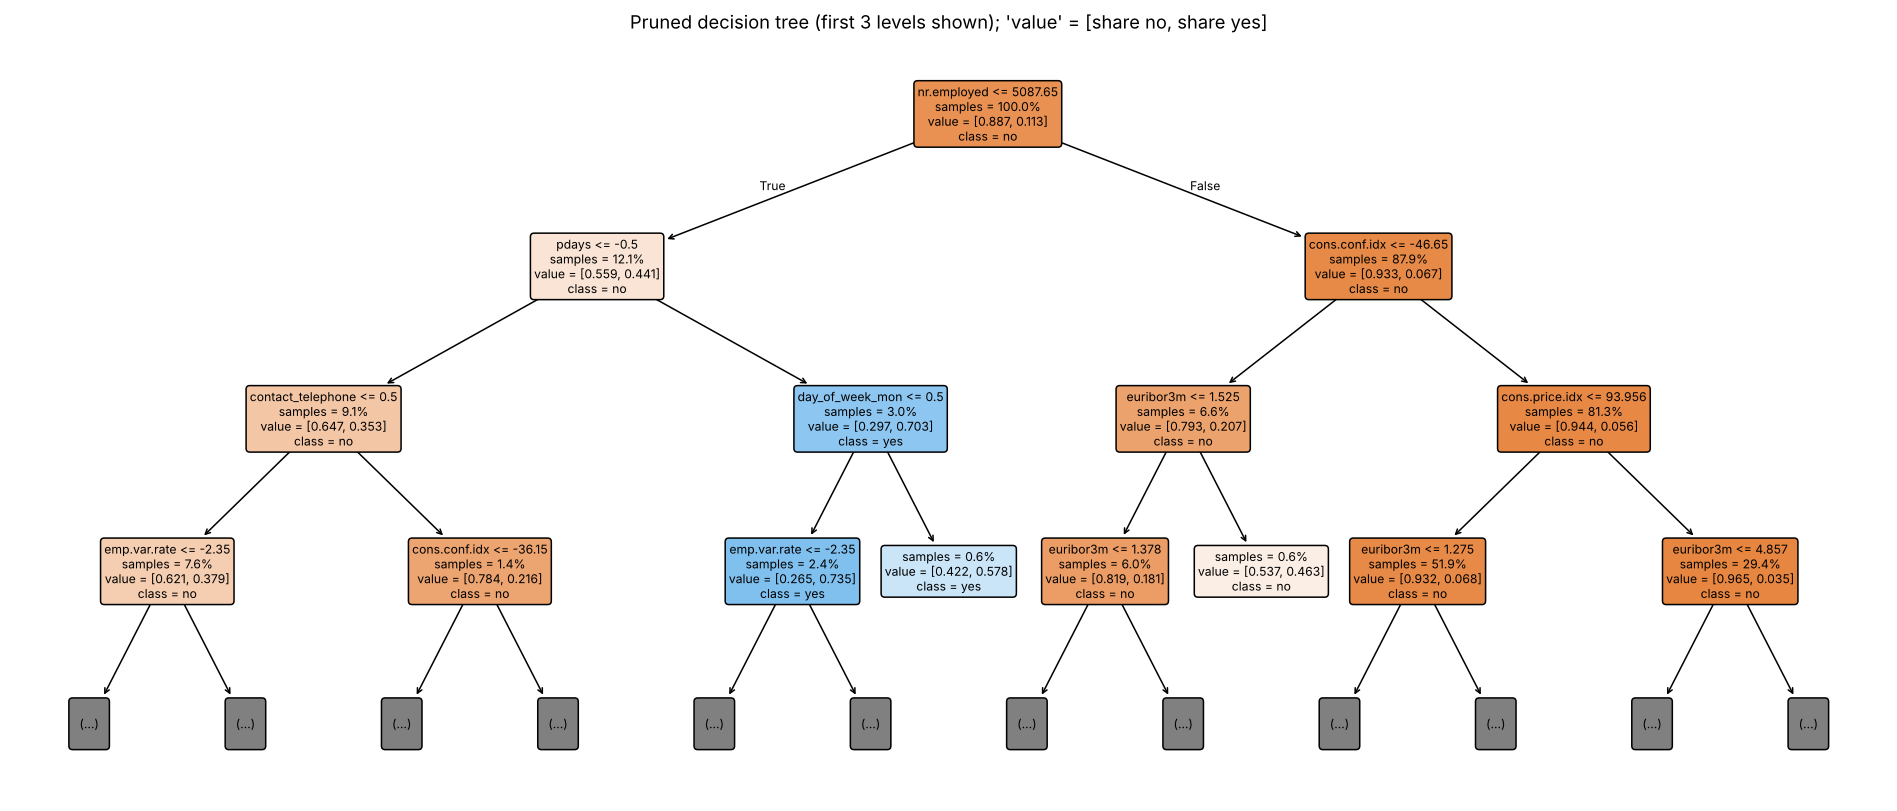

In [12]:
tree = tree_pipeline(NUMERIC, **TREE_PARAMS).fit(X_train, y_train)
tree_names = list(tree.named_steps["prep"].get_feature_names_out())
print(f"Leaves: {tree.named_steps['model'].get_n_leaves()}")

fig, ax = plt.subplots(figsize=(22, 9))
plot_tree(tree.named_steps["model"], feature_names=tree_names, class_names=["no", "yes"], max_depth=3,
          filled=True, impurity=False, proportion=True, rounded=True, fontsize=8, ax=ax)
ax.set_title("Pruned decision tree (first 3 levels shown); 'value' = [share no, share yes]")
plt.savefig(f"{FIG_DIR}/02_decision_tree.png", dpi=110, bbox_inches="tight"); plt.show()

In [13]:
# The same tree as text rules, all 5 levels. Each leaf line shows "weights: [no, yes]",
# the number of training clients in that leaf who did not / did subscribe.
print(export_text(tree.named_steps["model"], feature_names=tree_names, show_weights=True, decimals=2))

|--- nr.employed <= 5087.65
|   |--- pdays <= -0.50
|   |   |--- contact_telephone <= 0.50
|   |   |   |--- emp.var.rate <= -2.35
|   |   |   |   |--- euribor3m <= 0.74
|   |   |   |   |   |--- weights: [209.00, 159.00] class: 0
|   |   |   |   |--- euribor3m >  0.74
|   |   |   |   |   |--- weights: [901.00, 419.00] class: 0
|   |   |   |--- emp.var.rate >  -2.35
|   |   |   |   |--- previous <= 0.50
|   |   |   |   |   |--- weights: [223.00, 267.00] class: 1
|   |   |   |   |--- previous >  0.50
|   |   |   |   |   |--- weights: [228.00, 106.00] class: 0
|   |   |--- contact_telephone >  0.50
|   |   |   |--- cons.conf.idx <= -36.15
|   |   |   |   |--- weights: [227.00, 40.00] class: 0
|   |   |   |--- cons.conf.idx >  -36.15
|   |   |   |   |--- weights: [143.00, 62.00] class: 0
|   |--- pdays >  -0.50
|   |   |--- day_of_week_mon <= 0.50
|   |   |   |--- emp.var.rate <= -2.35
|   |   |   |   |--- weights: [108.00, 215.00] class: 1
|   |   |   |--- emp.var.rate >  -2.35
|   |   |  

**Reading the tree.**
- **The first question is about the economy** (employment level). The low-employment branch is the 2009–10 period, when subscription rates were far higher.
- **In that branch, the next questions are about the client's history and contact:** was the client contacted in a previous campaign (`pdays`), and by mobile or landline.
- **In the high-employment branch, the tree mostly keeps splitting on economic indicators**, with age, marital status and number of calls only near the bottom.
- A marketing manager can follow any branch and check whether it makes business sense, which is the decision tree's real advantage.
  It also shows plainly how much the economy dominates: something the forest's accuracy alone wouldn't reveal.

## 8. Random forest

A random forest builds **hundreds of trees**, each one:
1. trained on a **bootstrap sample**: clients drawn at random *with replacement*, so each tree sees a slightly different dataset;
2. allowed to consider only a **random subset of features** at each split (`max_features="sqrt"`: √(number of columns)), so the trees don't all ask the same questions.

The forest's probability is the **average** of the trees' probabilities. Individual trees overfit in different directions, and averaging cancels much of that out.

**Out-of-bag (OOB) score:** each tree never sees about a third of the training clients (those not drawn in its bootstrap sample).
Scoring each client using only the trees that didn't see it gives a free validation estimate.

In [14]:
def forest_pipeline(**params):
    prep = ColumnTransformer([("cat", OneHotEncoder(handle_unknown="ignore"), CATEGORICAL)],
                             remainder="passthrough", verbose_feature_names_out=False)
    return Pipeline([("prep", prep), ("model", RandomForestClassifier(random_state=RANDOM_STATE, n_jobs=-1, **params))])

rf_grid = GridSearchCV(forest_pipeline(n_estimators=200, max_features="sqrt"),
                       {"model__min_samples_leaf": [5, 10, 20, 50]}, cv=cv, scoring="roc_auc").fit(X_train, y_train)
print(pd.DataFrame(rf_grid.cv_results_)[["params", "mean_test_score", "std_test_score"]].to_string(index=False))

                         params  mean_test_score  std_test_score
 {'model__min_samples_leaf': 5}            0.794           0.008
{'model__min_samples_leaf': 10}            0.796           0.008
{'model__min_samples_leaf': 20}            0.797           0.009
{'model__min_samples_leaf': 50}            0.796           0.010


In [15]:
FOREST_PARAMS = {"n_estimators": 300, "min_samples_leaf": rf_grid.best_params_["model__min_samples_leaf"], "max_features": "sqrt"}
forest = forest_pipeline(oob_score=True, **FOREST_PARAMS).fit(X_train, y_train)
oob_auc = roc_auc_score(y_train, forest.named_steps["model"].oob_decision_function_[:, 1])
print(f"Selected settings: {FOREST_PARAMS}")
print(f"Out-of-bag AUC (free validation estimate): {oob_auc:.4f}")

Selected settings: {'n_estimators': 300, 'min_samples_leaf': 20, 'max_features': 'sqrt'}
Out-of-bag AUC (free validation estimate): 0.7966


## 9. Model comparison

Three models are compared on the untouched test set: the pruned decision tree, the random forest, and **logistic regression** as a familiar reference point
(one-hot categories plus standardised numeric columns).

**Metrics**
- **AUC**: probability that a random subscriber is ranked above a random non-subscriber (0.5 = random).
- **Average precision (AP)**, the area under the precision–recall curve: more informative than AUC when only 11% are positive,
  because it focuses on how clean the *top* of the ranked list is. A random ranking scores AP ≈ the base rate (0.113).

In [16]:
logit = Pipeline([("prep", ColumnTransformer([("cat", OneHotEncoder(handle_unknown="ignore"), CATEGORICAL),
                                              ("num", StandardScaler(), NUMERIC)])),
                  ("model", LogisticRegression(max_iter=3000))])

models = {"Decision tree (pruned)": tree, "Random forest": forest, "Logistic regression": logit.fit(X_train, y_train)}
cv_scores = {"Decision tree (pruned)": candidates.iloc[0]["mean_test_score"],
             "Random forest": rf_grid.best_score_,
             "Logistic regression": cross_val_score(logit, X_train, y_train, cv=cv, scoring="roc_auc").mean()}
p_test = {name: m.predict_proba(X_test)[:, 1] for name, m in models.items()}
comparison = pd.DataFrame({
    "cv_auc": cv_scores,
    "test_auc": {n: roc_auc_score(y_test, p) for n, p in p_test.items()},
    "test_average_precision": {n: average_precision_score(y_test, p) for n, p in p_test.items()},
})
comparison.loc["Random ranking", ["test_auc", "test_average_precision"]] = [0.5, y_test.mean()]
comparison

,cv_auc,test_auc,test_average_precision
Decision tree (pruned),0.782,0.797,0.447
Random forest,0.797,0.809,0.485
Logistic regression,0.790,0.800,0.453
Random ranking,NaN,0.500,0.113


**Reading the result**
- **The random forest is best** on both AUC and average precision, though only modestly ahead of the 22-leaf tree.
- **The pruned tree gets most of the way** with rules a person can read in full.
- **Logistic regression is close behind**: a reminder that a simpler model is often competitive. Section 14 shows where it actually wins.
- **Selected for scoring: the random forest.** The decision tree stays alongside it to *explain* each recommendation in the dashboard.

## 10. Gains and lift: who to call first

Rank test clients from most to least likely to subscribe (by the forest's probability), split them into 10 equal groups, and compare each group's
actual subscription rate with the overall rate. **Lift** = group rate ÷ overall rate.

In [17]:
p_rf = p_test["Random forest"]
d = pd.DataFrame({"y": y_test.values, "p": p_rf})
d["group"] = pd.qcut(d["p"].rank(method="first", ascending=False), 10, labels=range(1, 11))
gains = d.groupby("group", observed=True).agg(clients=("y", "size"), subscribers=("y", "sum"), actual_rate=("y", "mean"))
gains["lift"] = gains["actual_rate"] / d["y"].mean()
gains["cum_share_of_subscribers"] = gains["subscribers"].cumsum() / gains["subscribers"].sum()
gains

,clients,subscribers,actual_rate,lift,cum_share_of_subscribers
group,,,,,
1,824,429,0.521,4.621,0.462
2,824,183,0.222,1.971,0.659
3,823,66,0.080,0.712,0.731
4,824,56,0.068,0.603,0.791
5,823,36,0.044,0.388,0.830
6,824,40,0.049,0.431,0.873
7,823,35,0.043,0.377,0.911
8,824,28,0.034,0.302,0.941
9,823,26,0.032,0.280,0.969


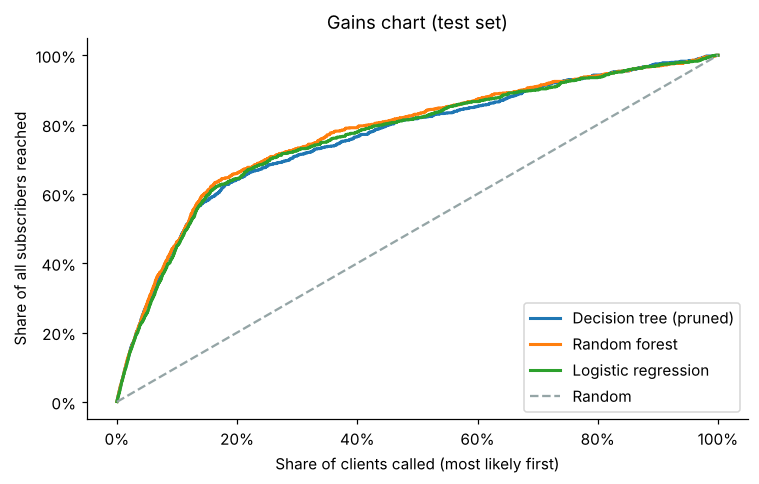

In [18]:
fig, ax = plt.subplots(figsize=(7, 4.5))
for name, p in p_test.items():
    order = np.argsort(-p)
    ax.plot(np.arange(1, len(p) + 1) / len(p), np.cumsum(y_test.values[order]) / y_test.sum(), lw=2, label=name)
ax.plot([0, 1], [0, 1], "--", color=GREY, label="Random")
ax.set_xlabel("Share of clients called (most likely first)"); ax.set_ylabel("Share of all subscribers reached")
ax.xaxis.set_major_formatter(PercentFormatter(1)); ax.yaxis.set_major_formatter(PercentFormatter(1)); ax.legend()
ax.set_title("Gains chart (test set)")
plt.tight_layout(); plt.savefig(f"{FIG_DIR}/03_gains.png", dpi=120, bbox_inches="tight"); plt.show()

Calling the top 10% of clients reaches nearly half of all subscribers, at more than four times the average conversion rate.
The top 20% reaches about two thirds.

## 11. Calibration

Ranking is what matters for "who to call first". For "how many to call" (Section 13), the probabilities themselves also need to be roughly right.

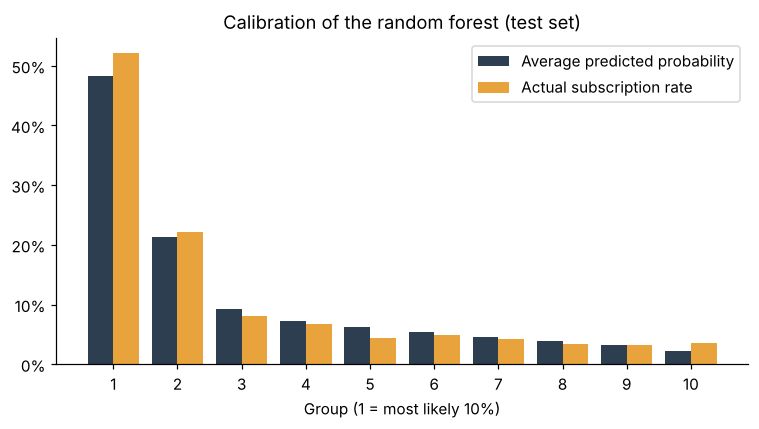

,avg_predicted,actual_rate
group,,
1,0.482,0.521
2,0.214,0.222
3,0.092,0.080
4,0.073,0.068
5,0.062,0.044
6,0.054,0.049
7,0.046,0.043
8,0.039,0.034
9,0.032,0.032


In [19]:
d["avg_predicted"] = p_rf
cal = d.groupby("group", observed=True).agg(avg_predicted=("p", "mean"), actual_rate=("y", "mean"))
fig, ax = plt.subplots(figsize=(7, 4))
x = np.arange(1, 11)
ax.bar(x - 0.2, cal["avg_predicted"], 0.4, color=NAVY, label="Average predicted probability")
ax.bar(x + 0.2, cal["actual_rate"], 0.4, color=AMBER, label="Actual subscription rate")
ax.set_xticks(x); ax.set_xlabel("Group (1 = most likely 10%)"); ax.yaxis.set_major_formatter(PercentFormatter(1)); ax.legend()
ax.set_title("Calibration of the random forest (test set)")
plt.tight_layout(); plt.savefig(f"{FIG_DIR}/04_calibration.png", dpi=120, bbox_inches="tight"); plt.show()
cal

The forest is reasonably calibrated in the middle and bottom of the list, but **under-predicts the top group**: averaging hundreds of trees pulls extreme
probabilities toward the middle, a known random-forest behaviour. Ranking is unaffected. If the probabilities were used directly (for example, to forecast
campaign volumes), a calibration step such as isotonic regression would be added.

## 12. Feature importance: impurity vs permutation

Two common ways to ask "which features matter?":
- **Impurity importance** (`feature_importances_`): how much each feature reduced Gini impurity across all splits in all trees.
  It is computed on *training* data and is known to **favour numeric features with many possible split points**.
- **Permutation importance**: shuffle one feature's values in the *test* set and measure how much the AUC drops. If shuffling a feature doesn't hurt, the model doesn't really rely on it.
  Shuffling is done on the original columns, so each categorical column is assessed as a whole rather than one dummy at a time.

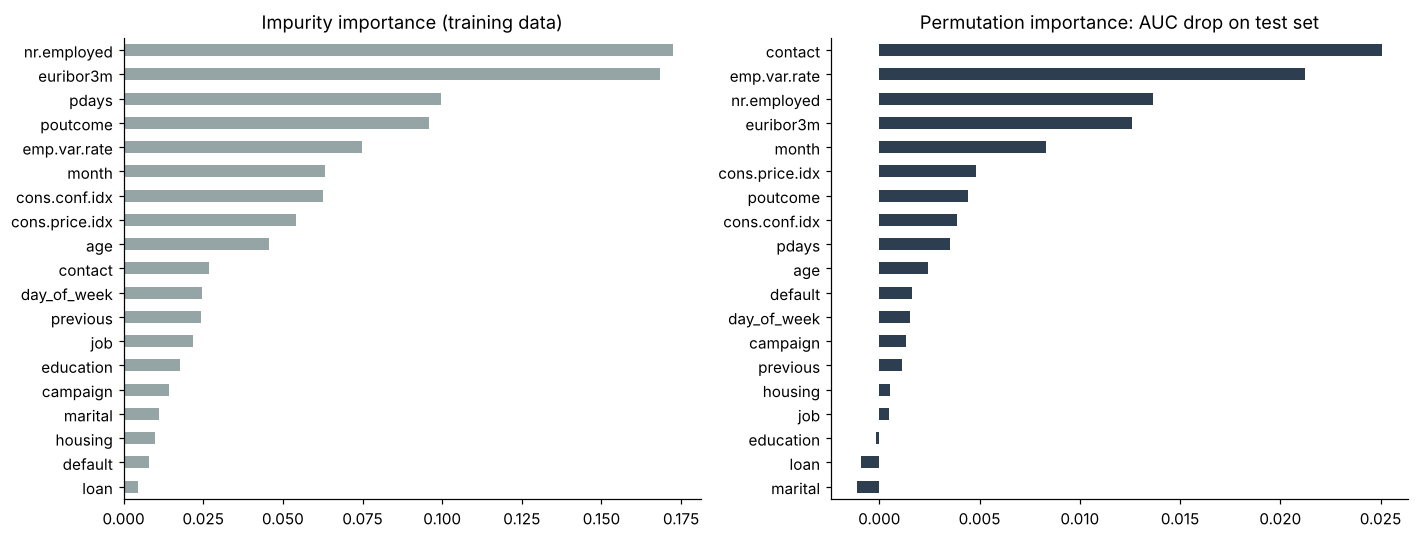

,impurity_importance,permutation_auc_drop
contact,0.027,0.025
emp.var.rate,0.075,0.021
nr.employed,0.172,0.014
euribor3m,0.169,0.013
month,0.063,0.008
cons.price.idx,0.054,0.005
poutcome,0.096,0.004
cons.conf.idx,0.063,0.004
pdays,0.100,0.004
age,0.046,0.002


In [20]:
# Impurity importance: summed over each original column's one-hot dummies
names_rf = forest.named_steps["prep"].get_feature_names_out()
imp = pd.Series(forest.named_steps["model"].feature_importances_, index=names_rf)
col_of = {n: next((c for c in CATEGORICAL if n.startswith(c + "_")), n) for n in names_rf}
impurity = imp.groupby(col_of).sum().sort_values(ascending=False)

perm = permutation_importance(forest, X_test, y_test, scoring="roc_auc", n_repeats=5, random_state=RANDOM_STATE, n_jobs=-1)
permutation = pd.Series(perm.importances_mean, index=FEATURES).sort_values(ascending=False)

both = pd.DataFrame({"impurity_importance": impurity, "permutation_auc_drop": permutation}).sort_values("permutation_auc_drop", ascending=False)
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
both["impurity_importance"].sort_values().plot.barh(ax=axes[0], color=GREY, title="Impurity importance (training data)")
both["permutation_auc_drop"].sort_values().plot.barh(ax=axes[1], color=NAVY, title="Permutation importance: AUC drop on test set")
plt.tight_layout(); plt.savefig(f"{FIG_DIR}/05_feature_importance.png", dpi=120, bbox_inches="tight"); plt.show()
both.round(4)

**What the two methods agree and disagree on**
- **They agree on the broad picture:** the economic indicators, contact type and previous-contact history matter; job, education, marital status and loans barely do.
- **Contact type is the clearest disagreement.** It ranks low on impurity importance because a yes/no feature offers only one possible split,
  yet shuffling it causes the biggest AUC drop of any feature. Meanwhile the continuous economic indicators (`nr.employed`, `euribor3m`), with many possible split points,
  take the largest impurity shares. That is the impurity-importance bias in action.
- **Overlapping features share the credit.** The economic indicators all move with the business cycle, and `pdays`, `poutcome` and `previous` all describe prior contact,
  so shuffling any one of them costs little: the others stand in. Permutation importance understates correlated features.
  Neither method is "the truth"; reporting both, and saying why they differ, is more honest.

## 13. Campaign economics: how many clients to call

Illustrative assumptions (the dashboard lets you change them):
- **Cost per call: €5** (agent time, including unanswered attempts)
- **Value per subscription: €50** (net margin earned on the deposit)

**Step by step.** Call clients in order of predicted probability. After calling the top *k*:

$$\text{profit}(k) = €50 \times \text{subscribers among the top } k \; - \; €5 \times k$$

**Break-even rule.** A call is worth making when its expected value exceeds its cost: p × €50 > €5, so **p > 5 ÷ 50 = 10%**.

Call everyone:     8,236 calls, 928 subscribers, profit = 50 x 928 - 5 x 8236 = €5,220
Best number to call: top 1,431 clients (17.4%), 597 subscribers (64.3% of all), profit = 50 x 597 - 5 x 1431 = €22,695
The last client worth calling has p = 0.139  (break-even rule: 0.100)


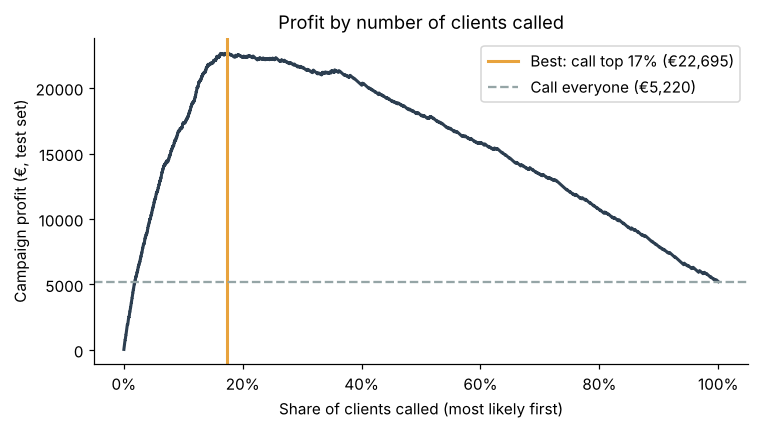

In [21]:
COST, VALUE = 5, 50
order = np.argsort(-p_rf)
calls = np.arange(1, len(order) + 1)
subscribers = np.cumsum(y_test.values[order])
profit = VALUE * subscribers - COST * calls
k = int(np.argmax(profit))

print(f"Call everyone:     {len(calls):,} calls, {subscribers[-1]:,} subscribers, profit = 50 x {subscribers[-1]} - 5 x {len(calls)} = €{profit[-1]:,}")
print(f"Best number to call: top {calls[k]:,} clients ({calls[k] / len(calls):.1%}), {subscribers[k]:,} subscribers "
      f"({subscribers[k] / subscribers[-1]:.1%} of all), profit = 50 x {subscribers[k]} - 5 x {calls[k]} = €{profit[k]:,}")
print(f"The last client worth calling has p = {p_rf[order][k]:.3f}  (break-even rule: {COST / VALUE:.3f})")

fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(calls / len(calls), profit, color=NAVY, lw=2)
ax.axvline(calls[k] / len(calls), color=AMBER, lw=2, label=f"Best: call top {calls[k] / len(calls):.0%} (€{profit[k]:,})")
ax.axhline(profit[-1], color=GREY, ls="--", label=f"Call everyone (€{profit[-1]:,})")
ax.set_xlabel("Share of clients called (most likely first)"); ax.set_ylabel("Campaign profit (€, test set)")
ax.xaxis.set_major_formatter(PercentFormatter(1)); ax.legend(); ax.set_title("Profit by number of clients called")
plt.tight_layout(); plt.savefig(f"{FIG_DIR}/06_profit_curve.png", dpi=120, bbox_inches="tight"); plt.show()

**Result:** calling the top ~17% earns over four times the profit of calling everyone, while still reaching well over half of all subscribers.
The empirical best cut-off (p ≈ 0.14) sits above the 10% break-even probability because clients with predicted probabilities in the 7–14% range actually
subscribe slightly *less* often than predicted (groups 3–5 in Section 11). With better-calibrated probabilities, the break-even rule and the empirical best would line up.

## 14. Out-of-time validation: does the model survive a changing economy?

The random split mixes all months into both train and test, so the test set looks like the training set. In real use, a model is trained on the past and used on the future.
The data is in date order, so here the models are trained on the **first 80% of contacts** and tested on the **last 20%**.

In [22]:
cut = int(len(data) * 0.8)
early, late = data.iloc[:cut], data.iloc[cut:]
print(f"Early period: {len(early):,} contacts, subscription rate {early[TARGET].mean():.1%}")
print(f"Late period:  {len(late):,} contacts, subscription rate {late[TARGET].mean():.1%}")
print(f"\nEuribor rate, early period: {early['euribor3m'].min():.2f}% to {early['euribor3m'].max():.2f}%")
print(f"Euribor rate, late period:  {late['euribor3m'].min():.2f}% to {late['euribor3m'].max():.2f}%")

Early period: 32,940 contacts, subscription rate 6.4%
Late period:  8,236 contacts, subscription rate 30.8%

Euribor rate, early period: 1.30% to 5.04%
Euribor rate, late period:  0.63% to 1.30%


In [23]:
oot_models = {"Decision tree (pruned)": tree_pipeline(NUMERIC, **TREE_PARAMS),
              "Random forest": forest_pipeline(**FOREST_PARAMS),
              "Logistic regression": Pipeline(logit.steps)}
rows = []
for name, m in oot_models.items():
    m.fit(early[FEATURES], early[TARGET])
    p = m.predict_proba(late[FEATURES])[:, 1]
    rows.append({"model": name, "random_split_test_auc": comparison.loc[name, "test_auc"],
                 "out_of_time_auc": roc_auc_score(late[TARGET], p),
                 "avg_predicted": p.mean(), "actual_rate": late[TARGET].mean()})
oot = pd.DataFrame(rows).set_index("model")
oot

,random_split_test_auc,out_of_time_auc,avg_predicted,actual_rate
model,,,,
Decision tree (pruned),0.797,0.510,0.069,0.308
Random forest,0.809,0.740,0.154,0.308
Logistic regression,0.800,0.749,0.266,0.308


**This is the most important result in the notebook.**
- **The late period is a different world:** the subscription rate jumped from about 6% to about 31%, and the Euribor rate fell to or below the **lowest** value seen in the early period.
- **All models lose accuracy, and all badly under-predict** the late-period rate: they learned 2008's baseline.
- **The decision tree collapses.** Trees can't extrapolate: every client with a Euribor rate below the lowest training value lands in the same branch as the lowest training values.
  The forest suffers less because averaging many trees smooths the effect.
- **Logistic regression holds up best, narrowly**, because a straight-line relationship *can* extend beyond the training range, roughly in the right direction here.

**What this means for model ownership**
1. A random-split test score **overstates** how well a model will do after deployment when conditions drift. Validate out of time before going live.
2. Monitor the *inputs*, not only the outputs: an input moving outside its training range (here, the Euribor rate) is an early warning that predictions can't be trusted.
3. Plan for **regular retraining**, and recalibrate the probabilities when the base rate shifts.
4. For features that drift, consider models that extrapolate sensibly, or features expressed as *changes* rather than levels.

## 15. Limitations and model ownership

**Limitations**
- **One bank, Portugal, 2008–2010**, a period that includes the financial crisis. The method transfers; the numbers don't.
- **The economic indicators dominate.** They set the campaign-wide baseline more than they distinguish between clients called on the same day.
- **Probabilities are compressed** at the top of the list (Section 11); fine for ranking, but they need calibration before being used as forecasts.
- **The cost and value figures are illustrative.** Real figures would come from finance (call-centre costs, deposit margins, client lifetime value).
- **Selection bias:** the bank chose whom to call, so the data only covers clients it decided to contact.

**If I owned this model in production**
| Area | Practice |
|---|---|
| Documentation | Model card: purpose, data, the `duration` exclusion and why, settings chosen and how, out-of-time results, limitations |
| Validation | Out-of-time test on the most recent months before every release, not just a random split |
| Monitoring | Each campaign: conversion rate by score group (does the top group still convert best?); input ranges, especially the economic indicators |
| Triggers | Inputs outside the training range, lift in the top group falling below an agreed level, or a base-rate shift → retrain and recalibrate |
| Fairness | Age is a model input; check that targeting by age is permitted and appropriate for the product, and review outcomes by age band |
| Governance | Version control, change log, sign-off by marketing and model risk |

**Code reuse:** the final models are also implemented in `src/marketing_model.py`, which powers the dashboard (`app.py`).
The automated tests in `tests/` confirm it reproduces this notebook's numbers.